# Model Experiments
Starter notebook. Implementation pending.

In [1]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

path = r"D:\ResistMap-AI\data\processed\klebsiella_amr_features.csv"
data = pd.read_csv(path)

gene_cols = [c for c in data.columns if c.startswith("gene__")]
frequency = data[gene_cols].mean()
selected = frequency[(frequency >= 0.01) & (frequency <= 0.99)].index
X = data[selected].to_numpy(dtype=float)

scores = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X)
    score = silhouette_score(
        X, labels, sample_size=1000, random_state=42
    )
    scores.append({"clusters": k, "silhouette": score})
    print(f"k={k}: silhouette={score:.3f}")

display(pd.DataFrame(scores))

k=2: silhouette=0.133
k=3: silhouette=0.133
k=4: silhouette=0.114
k=5: silhouette=0.122
k=6: silhouette=0.132
k=7: silhouette=0.135
k=8: silhouette=0.142


,clusters,silhouette
0,2,0.133214
1,3,0.132725
2,4,0.114195
3,5,0.121750
4,6,0.132195
5,7,0.134716
6,8,0.141763


In [2]:
from sklearn.cluster import KMeans
import pandas as pd

model = KMeans(n_clusters=8, n_init=10, random_state=42)
data["cluster"] = model.fit_predict(X)

print("Samples in each cluster:")
display(data["cluster"].value_counts().sort_index().rename("samples"))

# Each gene's overall and per-cluster frequency
overall = data[selected].mean()
cluster_freq = data.groupby("cluster")[list(selected)].mean()

for cluster_id in sorted(data["cluster"].unique()):
    difference = cluster_freq.loc[cluster_id] - overall
    top = difference.sort_values(ascending=False).head(8)

    print(f"\nCluster {cluster_id}: {sum(data['cluster'] == cluster_id)} samples")
    display(pd.DataFrame({
        "gene": top.index.str.removeprefix("gene__"),
        "cluster_frequency": cluster_freq.loc[cluster_id, top.index].round(3).values,
        "overall_frequency": overall[top.index].round(3).values
    }))

Samples in each cluster:


C:\Users\ASUS\AppData\Local\Temp\ipykernel_52492\3425692130.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data["cluster"] = model.fit_predict(X)


cluster
0    985
1    372
2    184
3    314
4    374
5    158
6    251
7    362
Name: samples, dtype: int64


Cluster 0: 985 samples


,gene,cluster_frequency,overall_frequency
0,oqxB19,0.289,0.204
1,fosA10,0.068,0.031
2,blaSHV-1,0.242,0.205
3,oqxA10,0.073,0.044
4,oqxB25,0.109,0.080
5,blaSHV-187,0.034,0.019
6,blaSHV-27,0.039,0.025
7,oqxB20,0.028,0.020



Cluster 1: 372 samples


... (9 outputs left out)


Cluster 6: 251 samples


,gene,cluster_frequency,overall_frequency
0,blaKPC-2,0.976,0.205
1,rmtB1,0.869,0.107
2,blaCTX-M-65,0.761,0.074
3,aadA2,0.717,0.274
4,blaLAP-2,0.486,0.071
5,catA2,0.454,0.094
6,blaTEM-1,0.861,0.533
7,tet(A),0.590,0.275



Cluster 7: 362 samples


,gene,cluster_frequency,overall_frequency
0,dfrA12,0.867,0.185
1,mrx(A),0.898,0.266
2,mph(A),0.898,0.267
3,aadA2,0.895,0.274
4,sul1,0.928,0.420
5,catA1,0.517,0.139
6,aac(6')-Ib,0.539,0.174
7,aph(3')-Ia,0.503,0.142


In [3]:
data = data.copy()
data["cluster"] = model.fit_predict(X)

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

runs = {}
for seed in [42, 7, 21, 99, 123]:
    runs[seed] = KMeans(
        n_clusters=8,
        n_init=10,
        random_state=seed
    ).fit_predict(X)

reference = runs[42]
stability = {
    seed: adjusted_rand_score(reference, labels)
    for seed, labels in runs.items()
    if seed != 42
}

display(pd.Series(stability, name="adjusted_rand_score"))
print("Mean stability:", round(sum(stability.values()) / len(stability), 3))

7      0.917459
21     0.863627
99     0.966240
123    0.970296
Name: adjusted_rand_score, dtype: float64

Mean stability: 0.929


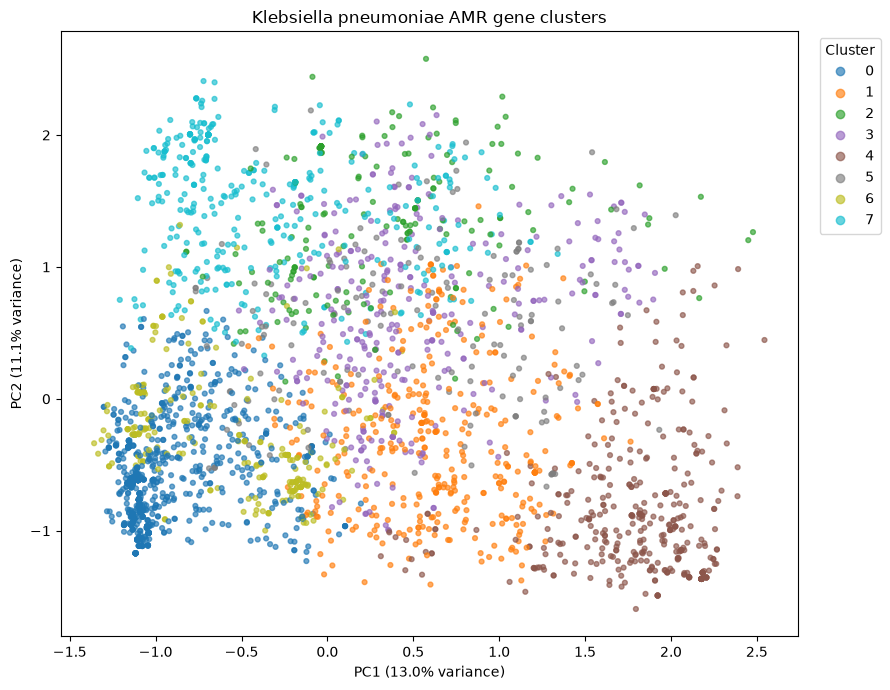

Variance shown in 2D: 24.1 %


In [5]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
points = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(9, 7))
scatter = ax.scatter(
    points[:, 0], points[:, 1],
    c=runs[42], cmap="tab10",
    s=12, alpha=0.65
)

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
ax.set_title("Klebsiella pneumoniae AMR gene clusters")
ax.legend(*scatter.legend_elements(), title="Cluster",
          bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("Variance shown in 2D:",
      round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

In [6]:
# Cluster labels from the stable k=8 run
labels = pd.Series(runs[42], index=data.index, name="cluster")
overall = data[list(selected)].mean()

rows = []
for cluster_id in sorted(labels.unique()):
    in_cluster = labels.eq(cluster_id)
    cluster_frequency = data.loc[in_cluster, list(selected)].mean()
    enrichment = (cluster_frequency - overall).sort_values(ascending=False)

    for gene_col in enrichment.head(5).index:
        rows.append({
            "cluster": cluster_id,
            "samples": int(in_cluster.sum()),
            "gene": gene_col.removeprefix("gene__"),
            "in_cluster_%": round(cluster_frequency[gene_col] * 100, 1),
            "overall_%": round(overall[gene_col] * 100, 1),
        })

profile = pd.DataFrame(rows)
display(profile)

,cluster,samples,gene,in_cluster_%,overall_%
0,0,985,oqxB19,28.9,20.4
1,0,985,fosA10,6.8,3.1
2,0,985,blaSHV-1,24.2,20.5
3,0,985,oqxA10,7.3,4.4
4,0,985,oqxB25,10.9,8.0
5,1,372,aph(6)-Id,92.7,31.9
6,1,372,aph(3'')-Ib,91.7,31.7
7,1,372,sul2,90.6,37.5
8,1,372,dfrA14,57.5,29.3
9,1,372,blaTEM-1,69.9,53.3


In [7]:
check = pd.DataFrame({
    "cluster": runs[42],
    "selected_gene_count": data[list(selected)].sum(axis=1),
    "all_complete_gene_count": data[gene_cols].sum(axis=1),
    "collection_year": data["collection_year"],
})

summary = check.groupby("cluster").agg(
    samples=("cluster", "size"),
    selected_genes_median=("selected_gene_count", "median"),
    selected_genes_mean=("selected_gene_count", "mean"),
    all_genes_median=("all_complete_gene_count", "median"),
    year_missing=("collection_year", lambda s: s.isna().sum()),
)

display(summary.round(1))

,samples,selected_genes_median,selected_genes_mean,all_genes_median,year_missing
cluster,,,,,
0,985,4.0,5.5,6.0,171
1,372,14.0,13.8,15.0,68
2,184,19.0,19.8,20.0,20
3,314,16.0,15.9,17.0,68
4,374,15.0,15.6,16.0,89
5,158,17.0,18.3,19.0,47
6,251,11.0,11.2,12.0,20
7,362,15.0,15.8,16.0,50


In [8]:
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
import pandas as pd

X_normalized = normalize(X, norm="l2")

normalized_model = KMeans(
    n_clusters=8, n_init=10, random_state=42
)
normalized_labels = normalized_model.fit_predict(X_normalized)

print("Original vs normalized clusters — ARI:",
      round(adjusted_rand_score(runs[42], normalized_labels), 3))

print("Normalized silhouette:",
      round(silhouette_score(
          X_normalized, normalized_labels,
          sample_size=1000, random_state=42
      ), 3))

display(pd.Series(normalized_labels).value_counts().sort_index())

Original vs normalized clusters — ARI: 0.441
Normalized silhouette: 0.111


0    358
1    518
2    148
3    438
4    350
5    276
6    503
7    409
Name: count, dtype: int64

In [9]:
from sklearn.metrics import pairwise_distances, silhouette_score, adjusted_rand_score
from sklearn.cluster import AgglomerativeClustering
import pandas as pd

X_binary = X.astype(bool)
jaccard_distance = pairwise_distances(X_binary, metric="jaccard")

jaccard_model = AgglomerativeClustering(
    n_clusters=8,
    metric="precomputed",
    linkage="average"
)
jaccard_labels = jaccard_model.fit_predict(jaccard_distance)

print("Jaccard silhouette:",
      round(silhouette_score(
          jaccard_distance, jaccard_labels,
          metric="precomputed",
          sample_size=1000,
          random_state=42
      ), 3))

print("ARI vs original KMeans:",
      round(adjusted_rand_score(runs[42], jaccard_labels), 3))

print("Cluster sizes:")
display(pd.Series(jaccard_labels).value_counts().sort_index())

Jaccard silhouette: 0.111
ARI vs original KMeans: 0.218
Cluster sizes:


0    1850
1     816
2       4
3     269
4      45
5       6
6       9
7       1
Name: count, dtype: int64

In [10]:
from pathlib import Path
from sklearn.ensemble import IsolationForest
import pandas as pd

detector = IsolationForest(
    n_estimators=300,
    contamination=0.03,
    random_state=42,
    n_jobs=-1
)
detector.fit(X)

analysis = data[[
    "Isolate", "Scientific name", "Collection date",
    "collection_year", "Location"
]].copy()

analysis["cluster"] = runs[42]
analysis["complete_gene_count"] = data[gene_cols].sum(axis=1).to_numpy()
analysis["anomaly_score"] = -detector.score_samples(X)
analysis["review_flag"] = detector.predict(X) == -1

print("Samples flagged for review:", int(analysis["review_flag"].sum()))
display(
    analysis.sort_values("anomaly_score", ascending=False).head(10)
)

output = Path(r"D:\ResistMap-AI\results\sample_analysis.csv")
output.parent.mkdir(parents=True, exist_ok=True)
analysis.to_csv(output, index=False)
print("Saved:", output)

Samples flagged for review: 90


,Isolate,Scientific name,Collection date,collection_year,Location,cluster,complete_gene_count,anomaly_score,review_flag
1258,PDT000460326.1,Klebsiella pneumoniae,2015-05,2015.0,China: Shandong,5,34,0.602359,True
453,PDT003000998.1,Klebsiella pneumoniae,2024-10-30,2024.0,China,5,34,0.600064,True
891,PDT003141248.1,Klebsiella pneumoniae,2023-08-31,2023.0,"China: Guangdong, Yunfu",5,34,0.598874,True
592,PDT003062392.1,Klebsiella pneumoniae,2017-04-12,2017.0,Kenya,5,32,0.598117,True
2511,PDT001378189.1,Klebsiella pneumoniae,2019-07-11,2019.0,China:Beijing,5,31,0.595967,True
2886,PDT000437246.1,Klebsiella pneumoniae,2004,2004.0,Viet Nam,3,37,0.589120,True
813,PDT001771730.1,Klebsiella pneumoniae,2019-12,2019.0,China,1,34,0.587639,True
725,PDT001095136.1,Klebsiella pneumoniae,NaN,NaN,UAE,2,34,0.580398,True
1277,PDT001995333.1,Klebsiella pneumoniae,2021-05,2021.0,China:Zhejiang,5,33,0.570464,True
1699,PDT002072469.1,Klebsiella pneumoniae,2024,2024.0,USA,2,30,0.569089,True


Saved: D:\ResistMap-AI\results\sample_analysis.csv


In [11]:
print("Median gene count by review flag:")
display(
    analysis.groupby("review_flag")["complete_gene_count"]
    .agg(["count", "median", "mean"])
    .round(1)
)

flagged = analysis["review_flag"].to_numpy()
flagged_rate = data.loc[flagged, list(selected)].mean()
overall_rate = data[list(selected)].mean()

comparison = pd.DataFrame({
    "flagged_%": (flagged_rate * 100).round(1),
    "overall_%": (overall_rate * 100).round(1),
})
comparison["difference_%"] = comparison["flagged_%"] - comparison["overall_%"]
comparison.index = comparison.index.str.removeprefix("gene__")

display(comparison.sort_values("difference_%", ascending=False).head(15))

Median gene count by review flag:


,count,median,mean
review_flag,,,
False,2910,14.0,13.2
True,90,25.5,26.6


,flagged_%,overall_%,difference_%
sul1,92.2,42.0,50.2
aadA1,64.4,15.8,48.6
mph(E),53.3,6.1,47.2
ble,63.3,17.1,46.2
msr(E),52.2,6.2,46.0
armA,48.9,5.2,43.7
mph(A),65.6,26.7,38.9
mrx(A),64.4,26.6,37.8
arr-2,38.9,5.6,33.3
floR,37.8,5.3,32.5


In [12]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import normalize
import pandas as pd

X_composition = normalize(X, norm="l2")

composition_detector = IsolationForest(
    n_estimators=300,
    contamination=0.03,
    random_state=42,
    n_jobs=-1
)
composition_detector.fit(X_composition)

composition_flag = composition_detector.predict(X_composition) == -1
composition_score = -composition_detector.score_samples(X_composition)

print("Flagged after normalization:", composition_flag.sum())
print("Flagged by both methods:",
      (analysis["review_flag"].to_numpy() & composition_flag).sum())

display(pd.DataFrame({
    "composition_flag": composition_flag,
    "gene_count": analysis["complete_gene_count"].to_numpy()
}).groupby("composition_flag")["gene_count"]
  .agg(["count", "median", "mean"])
  .round(1))

display(
    analysis.assign(
        composition_score=composition_score,
        composition_flag=composition_flag
    )
    .sort_values("composition_score", ascending=False)
    .head(10)
)

Flagged after normalization: 90
Flagged by both methods: 60


,count,median,mean
composition_flag,,,
False,2910,14.0,13.3
True,90,24.0,24.7


,Isolate,Scientific name,Collection date,collection_year,Location,cluster,complete_gene_count,anomaly_score,review_flag,composition_score,composition_flag
2511,PDT001378189.1,Klebsiella pneumoniae,2019-07-11,2019.0,China:Beijing,5,31,0.595967,True,0.512272,True
1258,PDT000460326.1,Klebsiella pneumoniae,2015-05,2015.0,China: Shandong,5,34,0.602359,True,0.511340,True
592,PDT003062392.1,Klebsiella pneumoniae,2017-04-12,2017.0,Kenya,5,32,0.598117,True,0.511167,True
891,PDT003141248.1,Klebsiella pneumoniae,2023-08-31,2023.0,"China: Guangdong, Yunfu",5,34,0.598874,True,0.508737,True
453,PDT003000998.1,Klebsiella pneumoniae,2024-10-30,2024.0,China,5,34,0.600064,True,0.503130,True
813,PDT001771730.1,Klebsiella pneumoniae,2019-12,2019.0,China,1,34,0.587639,True,0.501686,True
2643,PDT000433185.1,Klebsiella pneumoniae,2015,2015.0,Viet Nam:Ho Chi Minh,5,28,0.560701,True,0.499754,True
1401,PDT001983859.1,Klebsiella pneumoniae,2021-10,2021.0,China:Shandong,5,35,0.560535,True,0.495651,True
1277,PDT001995333.1,Klebsiella pneumoniae,2021-05,2021.0,China:Zhejiang,5,33,0.570464,True,0.494426,True
2886,PDT000437246.1,Klebsiella pneumoniae,2004,2004.0,Viet Nam,3,37,0.589120,True,0.487234,True
